# 00: Dataset Exploration, Cleaning & Split Preparation
**Course**: Foundations of Generative AI (ICT4403) - Assignment 3  
**Language Pair**: English (`en`) $\to$ Hindi (`hi`)  
**Dataset**: IIT Bombay English-Hindi Parallel Corpus (`cfilt/iitb-english-hindi`)

### Objectives
1. Mount Google Drive for persistent artifact storage.
2. Download the IITB English-Hindi corpus and inspect raw examples.
3. Perform Exploratory Data Analysis (EDA) on sentence lengths and word count distributions.
4. Clean the dataset: remove empty/whitespace rows, duplicate pairs, long sentences ($>40$ words), extreme length ratios ($<0.33$ or $>3.0$), and non-Devanagari targets ($<50\%$ Devanagari alphabetic characters).
5. Construct fixed, reproducible splits with seed `42` (Test: 1,000, Val: 1,000, Train: 50,000) ensuring **zero source overlap** between train and evaluation sets.
6. Export splits as JSONL files and generate `dataset_stats.json`.

## 1. Google Colab Environment Setup & Drive Mount

In [ ]:
# Google Drive Mount & Project Path Setup
import os
import sys

DRIVE_DIR = "/content/drive/MyDrive/mt-fgai-assignment3"

try:
    from google.colab import drive
    print("Mounting Google Drive...")
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
    print(f"Google Drive ready at: {DRIVE_DIR}")
except ImportError:
    print("Running locally.")
    DRIVE_DIR = "."

# Automatically set working directory to Drive project root if available
if os.path.exists(DRIVE_DIR) and os.path.exists(os.path.join(DRIVE_DIR, "configs", "config.yaml")):
    REPO_ROOT = DRIVE_DIR
    os.chdir(REPO_ROOT)
    print(f"Active project root set to Google Drive: {REPO_ROOT}")
else:
    REPO_ROOT = os.path.abspath(".")

if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

# Install pinned dependencies in Colab if needed
try:
    import google.colab
    !pip install -q transformers>=4.45.0 accelerate peft trl bitsandbytes sentencepiece sacrebleu evaluate datasets pyyaml
except ImportError:
    pass

# Display GPU hardware info
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU: {torch.cuda.get_device_name(0)}")
    !nvidia-smi


Mounting Google Drive...
Mounted at /content/drive
Google Drive ready at: /content/drive/MyDrive/mt-fgai-assignment3
Active project root set to Google Drive: /content/drive/MyDrive/mt-fgai-assignment3
PyTorch Version: 2.11.0+cu130
CUDA Available: True
Active GPU: Tesla T4
Fri Oct 30 12:31:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000

## 2. Load Central Configuration

In [ ]:
import yaml
from pprint import pprint

config_path = os.path.join(REPO_ROOT, "configs", "config.yaml")
with open(config_path, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("Loaded configuration:")
pprint(config["dataset"])
pprint(config["preprocessing"])
pprint(config["splits"])

Loaded configuration:
{'name': 'cfilt/iitb-english-hindi', 'src_lang': 'en', 'tgt_lang': 'hi'}
{'max_length_ratio': 3.0,
 'max_words': 40,
 'min_devanagari_alpha_ratio': 0.5,
 'min_length_ratio': 0.33}
{'llm_subset_size': 20000,
 'probe_random_samples': 20,
 'temperature_eval_size': 300,
 'test_size': 1000,
 'train_size': 50000,
 'val_size': 1000}


## 3. Load Raw IIT Bombay Dataset from Hugging Face

In [ ]:
from src.data import load_raw_iitb_dataset

raw_splits = load_raw_iitb_dataset(
    dataset_name=config["dataset"]["name"],
    src_lang=config["dataset"]["src_lang"],
    tgt_lang=config["dataset"]["tgt_lang"],
)

print("\n--- 5 Random Samples from Raw Training Set ---")
import random
random.seed(config["project"]["seed"])
for i, sample in enumerate(random.sample(raw_splits["train"], 5), 1):
    print(f"\nSample {i}:")
    print(f"  English: {sample['en']}")
    print(f"  Hindi  : {sample['hi']}")

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  190MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.7kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/1659083 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/520 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2507 [00:00<?, ? examples/s]


--- 5 Random Samples from Raw Training Set ---

Sample 1:
  English: Python lived coiled around a tall qunube tree.
  Hindi  : अजगर एक विशाल कुनुबे पेड़ को अपने गुंजलक में लपेटे पड़ा रहता था।

Sample 2:
  English: First page:
  Hindi  : à¤ªà¥à¤°à¤µà¤¿à¤·à¥à¤à¤¿ à¤à¥à¤¡à¤¼à¥à¤

Sample 3:
  English: Whether to show popup notifications when away or busy.
  Hindi  : क्या पॉप अप अधिसूचना दिखानी है जब दूर या व्यस्त है.

Sample 4:
  English: Women form a large part of the work force and constitute more than half of the artisan sector. It is estimated that over 70 lakh people are earning their livelihood from production of handicrafts and related activities.
  Hindi  : महिलाएं कार्यबल का एक बड़ा हिस्सा हैं और आधे से अधिक दस्तकारी क्षेत्र पर उनका प्रभुत्व है। यह अनुमान है कि 70 लाख से अधिक लोग हस्तशिल्प और संबंधित कार्यकलापों से अपनी आजीविका अर्जित कर रहे हैं।

Sample 5:
  English: “I have been asked to stay here because of security reasons, ” he says in justification in his regular int

## 4. Exploratory Data Analysis: Word Length Distributions
We inspect the length characteristics of English and Hindi sentences to determine optimal tokenization cutoffs.

Raw English - Mean: 13.0, Median: 9, 95th percentile: 40
Raw Hindi   - Mean: 14.0, Median: 9, 95th percentile: 43


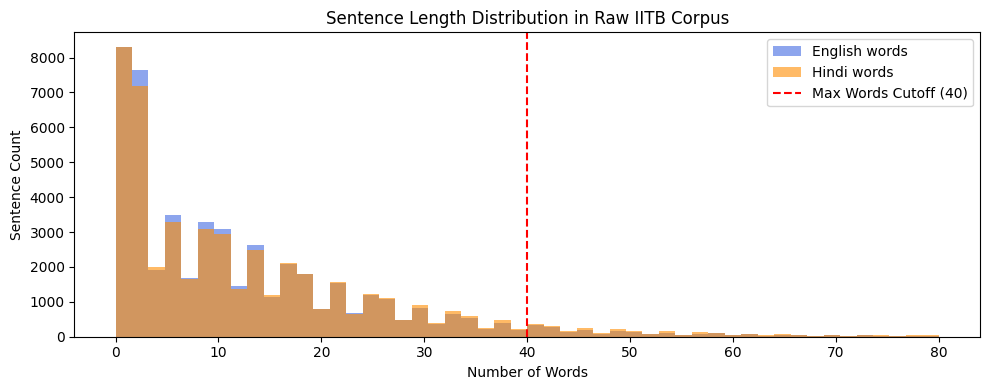

Saved histogram plot to results/plots/data_length_distribution_raw.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Sample 50,000 pairs from raw train for EDA
eda_sample = random.sample(raw_splits["train"], min(50000, len(raw_splits["train"])))
en_lengths = [len(x["en"].split()) for x in eda_sample]
hi_lengths = [len(x["hi"].split()) for x in eda_sample]

print(f"Raw English - Mean: {np.mean(en_lengths):.1f}, Median: {np.median(en_lengths):.0f}, 95th percentile: {np.percentile(en_lengths, 95):.0f}")
print(f"Raw Hindi   - Mean: {np.mean(hi_lengths):.1f}, Median: {np.median(hi_lengths):.0f}, 95th percentile: {np.percentile(hi_lengths, 95):.0f}")

os.makedirs("results/plots", exist_ok=True)
plt.figure(figsize=(10, 4))
plt.hist(en_lengths, bins=50, range=(0, 80), alpha=0.6, label='English words', color='royalblue')
plt.hist(hi_lengths, bins=50, range=(0, 80), alpha=0.6, label='Hindi words', color='darkorange')
plt.axvline(config["preprocessing"]["max_words"], color='red', linestyle='--', label=f'Max Words Cutoff ({config["preprocessing"]["max_words"]})')
plt.title('Sentence Length Distribution in Raw IITB Corpus')
plt.xlabel('Number of Words')
plt.ylabel('Sentence Count')
plt.legend()
plt.tight_layout()
plt.savefig('results/plots/data_length_distribution_raw.png', dpi=300)
plt.show()
print("Saved histogram plot to results/plots/data_length_distribution_raw.png")

## 5. Cleaning & Split Construction (Deterministic Seed = 42)
We apply:
- Max word threshold: $\le 40$ words.
- Length ratio bounds: $0.33 \le \text{len}(en)/\text{len}(hi) \le 3.0$.
- Devanagari ratio: $\ge 50\%$ of alphabetic characters in Hindi must be Devanagari.
- Strict deduplication and zero train-test source sentence overlap.

In [ ]:
from src.data import build_deterministic_splits, save_splits_as_jsonl

train_data, val_data, test_data, stats = build_deterministic_splits(
    raw_splits=raw_splits,
    seed=config["project"]["seed"],
    train_size=config["splits"]["train_size"],
    val_size=config["splits"]["val_size"],
    test_size=config["splits"]["test_size"],
    max_words=config["preprocessing"]["max_words"],
    min_ratio=config["preprocessing"]["min_length_ratio"],
    max_ratio=config["preprocessing"]["max_length_ratio"],
    min_devanagari_alpha_ratio=config["preprocessing"]["min_devanagari_alpha_ratio"],
)

# Export to data/splits/
splits_dir = os.path.join(REPO_ROOT, config["paths"]["splits_dir"])
save_splits_as_jsonl(train_data, val_data, test_data, stats, output_dir=splits_dir)

# Also backup to Google Drive if connected
if DRIVE_DIR != ".":
    drive_splits = os.path.join(DRIVE_DIR, "data", "splits")
    save_splits_as_jsonl(train_data, val_data, test_data, stats, output_dir=drive_splits)
    print(f"Backed up splits to Google Drive at: {drive_splits}")

Backed up splits to Google Drive at: /content/drive/MyDrive/mt-fgai-assignment3/data/splits


## 6. Dataset Statistics Summary Table

In [ ]:
import pandas as pd

summary_rows = [
    {"Split": "Train", "Sentence Pairs": f"{len(train_data):,}", "Avg EN Words": stats['train_statistics']['avg_en_words'], "Avg HI Words": stats['train_statistics']['avg_hi_words']},
    {"Split": "Validation", "Sentence Pairs": f"{len(val_data):,}", "Avg EN Words": round(np.mean([len(x['en'].split()) for x in val_data]), 2), "Avg HI Words": round(np.mean([len(x['hi'].split()) for x in val_data]), 2)},
    {"Split": "Test", "Sentence Pairs": f"{len(test_data):,}", "Avg EN Words": round(np.mean([len(x['en'].split()) for x in test_data]), 2), "Avg HI Words": round(np.mean([len(x['hi'].split()) for x in test_data]), 2)},
]

df_summary = pd.DataFrame(summary_rows)
print("\n--- Split Summary Table ---")
print(df_summary.to_markdown(index=False))
print(f"\nMedian Hindi-to-English word ratio in clean training data: {stats['train_statistics']['median_hi_en_word_ratio']}")


--- Split Summary Table ---
| Split      | Sentence Pairs   |   Avg EN Words |   Avg HI Words |
|:-----------|:-----------------|---------------:|---------------:|
| Train      | 50,000           |          11.39 |          12.13 |
| Validation | 1,000            |          11.47 |          12.24 |
| Test       | 1,000            |          17.73 |          20.38 |

Median Hindi-to-English word ratio in clean training data: 1.0
